# Prerequisite 07B · 从多臂老虎机走进强化学习

[上一章：Gymnasium](Prerequisite07_Gymnasium.ipynb) · [预备篇导航](Prerequisite00_Index.ipynb) · [下一章：入学测试](Prerequisite08_Readiness_Check.ipynb)

**为什么先学老虎机：**原书第 1 章直接介绍 MDP、策略、价值等一整套概念。没有机器学习背景时，
一次接收这么多新词很容易只记住名字。多臂老虎机是**最简单的强化学习问题**——没有状态、没有延迟奖励，
但已经包含 RL 最核心的两件事：

1. **从奖励中估计价值**（增量更新）；
2. **探索与利用的权衡**（ε-greedy、UCB）。

最后一节把它一步步扩展成 Q-learning，让你带着直觉进入 Chapter01。建议时长：3–4 小时。


## 1. 问题：10 台老虎机，哪台最赚钱？

- 每台机器（“臂”，arm）拉一次给一个随机奖励，均值未知、各不相同；
- 你只能通过拉动来了解它们；总次数有限；
- 目标：总奖励尽可能多。

和监督学习的区别：**没有人告诉你正确答案**，只告诉你“这次拉得怎么样”。你还得自己决定收集什么数据。


In [1]:
import numpy as np
import matplotlib.pyplot as plt

class Bandit:
    def __init__(self, k=10, seed=0):
        self.rng = np.random.default_rng(seed)
        self.true_means = self.rng.normal(0, 1, size=k)   # 每台机器的真实均值（agent 看不到）
        self.k = k

    def pull(self, arm):
        return self.rng.normal(self.true_means[arm], 1.0)  # 奖励 = 真实均值 + 噪声

bandit = Bandit()
print("最好的机器是:", bandit.true_means.argmax(), " 真实均值:", np.round(bandit.true_means, 2))
print("拉 3 次 0 号机:", [round(bandit.pull(0), 2) for _ in range(3)], "（同一台机器每次结果不同）")


最好的机器是: 6  真实均值: [ 0.13 -0.13  0.64  0.1  -0.54  0.36  1.3   0.95 -0.7  -1.27]
拉 3 次 0 号机: [-0.5, 0.17, -2.2] （同一台机器每次结果不同）


## 2. 估计价值：增量平均

动作价值 $Q(a)$ = 拉第 $a$ 台机器的**期望奖励**。最朴素的估计就是“历次奖励的平均值”。
不必存下所有历史，可以增量更新：

$$Q_{n+1}=Q_n+\frac1n\,(R_n-Q_n)$$

读作：**新估计 = 旧估计 + 步长 × (目标 − 旧估计)**。括号里的“目标 − 旧估计”是误差，后面的 TD error、DQN loss 都是它的变体。
如果环境会变化，把 $1/n$ 换成常数 $\alpha$，让新数据权重更大。


In [2]:
estimate, rewards = 0.0, []
for n in range(1, 201):
    r = bandit.pull(3)
    rewards.append(r)
    estimate += (r - estimate) / n
print("增量更新结果:", round(estimate, 4), " 直接求平均:", round(np.mean(rewards), 4))
print("3 号机真实均值:", round(bandit.true_means[3], 4))


增量更新结果: 0.1285  直接求平均: 0.1285
3 号机真实均值: 0.1049


## 3. 探索与利用：只选“当前最好”为什么会失败

- **利用（exploit）：**选当前估计最高的机器；
- **探索（explore）：**试试别的机器，也许它其实更好。

纯贪心（ε=0）可能一开始碰巧选到一台还不错的机器，以后再也不试别的。ε-greedy 以小概率 ε 随机探索。
下面在 200 个不同的老虎机问题上平均比较——**单次运行的结论不可信，这个习惯请一直保持**。


eps=0.0  : 最后 200 步平均奖励 1.044, 选中最优机器比例 35.50%


eps=0.01 : 最后 200 步平均奖励 1.264, 选中最优机器比例 60.22%


eps=0.1  : 最后 200 步平均奖励 1.331, 选中最优机器比例 78.92%


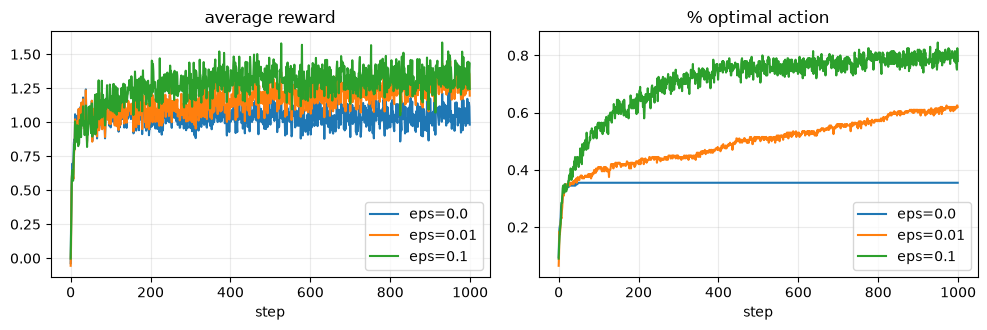

In [3]:
def run(epsilon, steps=1000, runs=200, seed=0):
    rng = np.random.default_rng(seed)
    avg_reward = np.zeros(steps); optimal = np.zeros(steps)
    for run_id in range(runs):
        b = Bandit(seed=seed * 10_000 + run_id)
        q, n = np.zeros(b.k), np.zeros(b.k)
        best = b.true_means.argmax()
        for t in range(steps):
            if rng.random() < epsilon:
                a = int(rng.integers(b.k))
            else:
                a = int(rng.choice(np.flatnonzero(q == q.max())))
            r = b.pull(a)
            n[a] += 1; q[a] += (r - q[a]) / n[a]
            avg_reward[t] += r; optimal[t] += (a == best)
    return avg_reward / runs, optimal / runs

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for eps in (0.0, 0.01, 0.1):
    reward_curve, optimal_curve = run(eps)
    axes[0].plot(reward_curve, label=f"eps={eps}"); axes[1].plot(optimal_curve, label=f"eps={eps}")
    print(f"eps={eps:<5}: 最后 200 步平均奖励 {reward_curve[-200:].mean():.3f}, 选中最优机器比例 {optimal_curve[-200:].mean():.2%}")
axes[0].set_title("average reward"); axes[1].set_title("% optimal action")
for ax in axes: ax.set_xlabel("step"); ax.legend(); ax.grid(alpha=.25)
plt.tight_layout(); plt.show(); plt.close()


**怎样读这张图：**ε=0 很快停在较低水平；ε=0.1 学得快但永远有 10% 的“浪费”；ε=0.01 起步慢、长期可能更好。
没有绝对最好的 ε——这就是为什么 DQN 里 ε 会从 1.0 **逐渐衰减**到 0.01 左右。

另一种思路是 **UCB**：给“试得少”的动作加探索奖励 $c\sqrt{\ln t / N(a)}$，不确定性越大越值得试。
第 18 章“高级探索”会把这个想法推广到复杂环境。

## 4. 从老虎机到完整强化学习

| | 多臂老虎机 | 表格 Q-learning（Ch05–06） | DQN（Ch06） |
|---|---|---|---|
| 状态 | 无 | 有限个，用编号表示 | 向量或图像 |
| 估计对象 | $Q(a)$ | $Q(s,a)$ 表格 | 神经网络 $Q_\theta(s,a)$ |
| 目标值 | 即时奖励 $r$ | $r+\gamma\max_{a'}Q(s',a')$ | 同左，但用 target network 计算 |
| 更新 | $Q\mathrel{+}=\alpha(r-Q)$ | $Q\mathrel{+}=\alpha(\text{target}-Q)$ | 对 $(\text{target}-Q_\theta)^2$ 做梯度下降 |
| 探索 | ε-greedy / UCB | ε-greedy | ε 衰减 |

**只多了两件事：**
1. **状态：**最好的动作取决于你在哪里；
2. **延迟奖励：**现在的动作会影响以后的奖励，所以 target 里要加上“下一状态的价值”乘以折扣 $\gamma$。

下面的 5 格走廊只在最右端给奖励 +1。观察奖励信息怎样**一轮一轮往左传播**——这就是 Chapter05 Bellman 方程的直觉。


In [4]:
n_states, gamma, alpha = 5, 0.9, 0.5
Q = np.zeros((n_states, 2))   # 动作 0=左, 1=右；状态 4 右边是终点
rng = np.random.default_rng(1)
snapshots = []
for episode in range(60):
    s = 0
    for _ in range(50):
        a = int(rng.integers(2))                       # 纯随机探索也能学会（Q-learning 是 off-policy）
        s_next = max(s - 1, 0) if a == 0 else s + 1
        terminated = s_next == n_states
        r = 1.0 if terminated else 0.0
        target = r if terminated else r + gamma * Q[s_next].max()
        Q[s, a] += alpha * (target - Q[s, a])
        if terminated: break
        s = s_next
    if episode in (0, 2, 5, 59):
        snapshots.append((episode + 1, Q[:, 1].copy()))

for ep, values in snapshots:
    print(f"第 {ep:>2} 轮后 Q(s, 右):", np.round(values, 3))
print("理论值 γ^(4-s):           ", np.round(gamma ** np.arange(4, -1, -1), 3))


第  1 轮后 Q(s, 右): [0.  0.  0.  0.  0.5]
第  3 轮后 Q(s, 右): [0.131 0.222 0.324 0.422 0.75 ]
第  6 轮后 Q(s, 右): [0.387 0.504 0.618 0.78  0.969]
第 60 轮后 Q(s, 右): [0.656 0.729 0.81  0.9   1.   ]
理论值 γ^(4-s):            [0.656 0.729 0.81  0.9   1.   ]


这个例子没有任何神经网络，却已经包含 Chapter01–06 的主干：**状态、动作、奖励、折扣、价值、探索、TD 更新**。
进入 Chapter01 时，把书中的新名词往这张表里对号入座即可。

## 5. 常见误区

- **“奖励高的动作就是好动作”：**在有状态的问题里，眼前奖励低的动作可能通向更大的未来奖励。
- **探索越多越好：**探索有代价；训练时探索、评估时关闭探索（ε=0）是标准做法。
- **初始全 0 + argmax：**并列时 `argmax` 总返回第一个，会悄悄变成“永远选动作 0”。


## 自动批改练习

每道题先读题、再写代码、最后运行同一格。看到 `[通过]` 才算完成；`[未通过]` 会说明哪里不对。
参考答案默认折叠，建议独立尝试至少 10 分钟后再看。


In [5]:
# 自动检查工具：每道练习末尾都会调用 check(test_xxx)。
# 未完成或有错时只打印提示，不会中断 Run All。
def check(test):
    try:
        test()
    except NotImplementedError:
        print(f"[未完成] {test.__name__}：把 raise NotImplementedError 换成你的代码，再运行本格。")
    except AssertionError as error:
        print(f"[未通过] {test.__name__}：{error}")
    except Exception as error:  # 代码本身报错，也给出可读提示
        print(f"[代码报错] {test.__name__}：{type(error).__name__}: {error}")
    else:
        print(f"[通过] {test.__name__}")


### 练习 1：增量更新

实现 `incremental_update(estimate, target, step_size)`，返回
$\text{estimate} + \text{step\_size}\times(\text{target}-\text{estimate})$。
这一行公式会在 Q-learning、TD、DQN 的 loss 中反复出现，只是 target 越来越复杂。


In [6]:
def incremental_update(estimate, target, step_size):
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
def test_incremental_update():
    assert incremental_update(0.0, 10.0, 0.1) == 1.0, "0 + 0.1*(10-0) = 1"
    estimate = 0.0
    for n, reward in enumerate([2.0, 4.0, 6.0], start=1):
        estimate = incremental_update(estimate, reward, 1 / n)
    assert abs(estimate - 4.0) < 1e-9, "步长取 1/n 时，增量更新应等于普通平均 4.0"

check(test_incremental_update)


[未完成] test_incremental_update：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
def incremental_update(estimate, target, step_size):
    return estimate + step_size * (target - estimate)
```

</details>


### 练习 2：带随机平局处理的 ε-greedy

实现 `epsilon_greedy(q, epsilon, rng)`：以概率 `epsilon` 均匀随机选动作；否则选 Q 最大的动作，
**若有多个并列最大值，在它们之间随机选**（否则初始全 0 时会永远选动作 0）。返回 `int`。

<details><summary>提示（卡住 10 分钟再看）</summary>

`best = np.flatnonzero(q == q.max())`，再 `rng.choice(best)`。

</details>


In [7]:
import numpy as np

def epsilon_greedy(q, epsilon, rng):
    q = np.asarray(q, dtype=float)
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
import numpy as np

def test_epsilon_greedy():
    rng = np.random.default_rng(0)
    picks = [epsilon_greedy([0.0, 5.0, 1.0], 0.0, rng) for _ in range(50)]
    assert set(picks) == {1}, "epsilon=0 时应总选 Q 最大的动作 1"
    ties = [epsilon_greedy([0.0, 0.0, 0.0], 0.0, rng) for _ in range(300)]
    assert set(ties) == {0, 1, 2}, "全部并列时应在并列动作中随机选，不能总选 0"
    explore = [epsilon_greedy([0.0, 5.0, 1.0], 1.0, rng) for _ in range(300)]
    assert set(explore) == {0, 1, 2}, "epsilon=1 时应完全随机"
    assert isinstance(picks[0], int), "返回值应为 int"

check(test_epsilon_greedy)


[未完成] test_epsilon_greedy：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np

def epsilon_greedy(q, epsilon, rng):
    q = np.asarray(q, dtype=float)
    if rng.random() < epsilon:
        return int(rng.integers(len(q)))
    best = np.flatnonzero(q == q.max())
    return int(rng.choice(best))
```

</details>


### 练习 3：UCB 动作选择

UCB 给“试得少的动作”加奖励分：$a=\arg\max_a\left[Q(a)+c\sqrt{\frac{\ln t}{N(a)}}\right]$。
实现 `ucb_action(q, counts, t, c=2.0)`：若有 `counts==0` 的动作，先返回其中**编号最小**的一个；否则按公式选最大者。


In [8]:
import numpy as np

def ucb_action(q, counts, t, c=2.0):
    q = np.asarray(q, dtype=float); counts = np.asarray(counts, dtype=float)
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
def test_ucb_action():
    assert ucb_action([1.0, 0.0, 0.0], [3, 0, 0], t=3) == 1, "有没试过的动作时，先试编号最小的那个"
    assert ucb_action([1.0, 0.9], [100, 100], t=200) == 0, "次数相同时选 Q 更大的"
    assert ucb_action([1.0, 0.9], [1000, 2], t=1002) == 1, "试得很少的动作应得到较大的探索加分"

check(test_ucb_action)


[未完成] test_ucb_action：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np

def ucb_action(q, counts, t, c=2.0):
    q = np.asarray(q, dtype=float); counts = np.asarray(counts, dtype=float)
    untried = np.flatnonzero(counts == 0)
    if len(untried):
        return int(untried[0])
    return int(np.argmax(q + c * np.sqrt(np.log(t) / counts)))
```

</details>


### 练习 4：从老虎机到 Q-learning 的一步更新

把老虎机的增量更新加上“状态”和“未来”：
$$Q(s,a)\leftarrow Q(s,a)+\alpha\big[r+\gamma(1-\text{terminated})\max_{a'}Q(s',a')-Q(s,a)\big]$$
实现 `q_learning_update(Q, s, a, r, s_next, terminated, alpha, gamma)`：**原地**修改二维数组 `Q`，并返回 TD error。

<details><summary>提示（卡住 10 分钟再看）</summary>

先算 `target`，再 `td_error = target - Q[s, a]`，最后 `Q[s, a] += alpha * td_error`。

</details>


In [9]:
import numpy as np

def q_learning_update(Q, s, a, r, s_next, terminated, alpha, gamma):
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
import numpy as np

def test_q_learning_update():
    Q = np.zeros((3, 2)); Q[1] = [2.0, 5.0]
    err = q_learning_update(Q, 0, 1, 1.0, 1, False, alpha=0.5, gamma=0.9)
    assert abs(err - 5.5) < 1e-9, f"TD error = 1 + 0.9*5 - 0 = 5.5，得到 {err}"
    assert abs(Q[0, 1] - 2.75) < 1e-9, "Q[0,1] 应原地更新为 0 + 0.5*5.5 = 2.75"
    err2 = q_learning_update(Q, 1, 0, 1.0, 2, True, alpha=1.0, gamma=0.9)
    assert abs(Q[1, 0] - 1.0) < 1e-9, "terminated=True 时不应加未来价值，Q[1,0] 应为 1"

check(test_q_learning_update)


[未完成] test_q_learning_update：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np

def q_learning_update(Q, s, a, r, s_next, terminated, alpha, gamma):
    future = 0.0 if terminated else gamma * Q[s_next].max()
    td_error = r + future - Q[s, a]
    Q[s, a] += alpha * td_error
    return float(td_error)
```

</details>


## 过关标准

- [ ] 4 道练习全部 `[通过]`；
- [ ] 能用一句话解释“新估计 = 旧估计 + 步长 × (目标 − 旧估计)”里每一项；
- [ ] 能解释为什么 ε=0 会卡住、为什么 DQN 的 ε 要衰减；
- [ ] 能说出从老虎机到 Q-learning 多出来的两件事。

**选读：**[Sutton & Barto 第 2 章 Multi-armed Bandits](http://incompleteideas.net/book/the-book-2nd.html)（本课的思想来源，经典教材，免费在线阅读）；
中文入门可参考 [Datawhale《蘑菇书 EasyRL》](https://datawhalechina.github.io/easy-rl/)。
